# Лабораторная работа № 3. Кластеризация

**Петрухно В. К. АП-327** 

**Тема:** изучение алгоритмов кластеризации, оценка качества разбиения данных на кластеры и интерпретация результатов.

**Датасет:** Seeds Dataset (геометрические характеристики зёрен пшеницы).

**Методы:** K-means и агломеративная иерархическая кластеризация (Agglomerative Clustering).

> 

## 1. Введение

Кластеризация относится к методам обучения без учителя: алгоритм получает матрицу признаков `X` и самостоятельно выявляет группы похожих объектов. Цель данной работы — исследовать структуру набора измерений зёрен пшеницы, сравнить два алгоритма кластеризации, подобрать параметры и оценить качество полученных групп.



## 2. Импорт библиотек и настройка

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import shapiro

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, rand_score, normalized_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score,
    pairwise_distances
)
from sklearn.feature_selection import f_classif

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Библиотеки импортированы. NumPy:", np.__version__, "| pandas:", pd.__version__)

Библиотеки импортированы. NumPy: 2.5.3 | pandas: 3.0.6


**Пояснение.** Подключены библиотеки для обработки таблиц, визуализации, стандартизации, кластеризации, иерархического анализа и расчёта метрик. `RANDOM_STATE = 42` обеспечивает воспроизводимость случайной инициализации K-means. 

## 3. Описание датасета и первичный анализ

### 3.1. Загрузка данных

In [2]:
# Файл должен лежать рядом с ноутбуком.
DATA_PATH = "seeds_dataset.txt"

column_names = [
    "Area", "Perimeter", "Compactness", "Kernel_length",
    "Kernel_width", "Asymmetry", "Groove_length", "Class"
]

data = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=column_names)

feature_names = column_names[:-1]
X = data[feature_names].copy()
y_true = data["Class"].astype(int).copy()  # только для внешней оценки

print("Размер таблицы:", data.shape)
print("Размер матрицы признаков X:", X.shape)
print("Число объектов в каждом исходном классе:")
display(y_true.value_counts().sort_index().rename(index={1: "Kama", 2: "Rosa", 3: "Canadian"}).to_frame("Количество"))
display(data.head())

Размер таблицы: (210, 8)
Размер матрицы признаков X: (210, 7)
Число объектов в каждом исходном классе:


,Количество
Class,
Kama,70
Rosa,70
Canadian,70


,Area,Perimeter,Compactness,Kernel_length,Kernel_width,Asymmetry,Groove_length,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


**Пояснение.** Загружено 210 строк и 8 столбцов: семь измеряемых числовых характеристик и один столбец с исходной разновидностью пшеницы. В исходном наборе представлены три разновидности — Kama, Rosa и Canadian, по 70 объектов каждой. Для кластеризации используется только `X` (210 × 7). Столбец `Class` сохранён в `y_true` и не передаётся алгоритмам, чтобы не превращать задачу без учителя в классификацию.

### 3.2. Структура, типы и пропуски

In [3]:
print("Информация о столбцах:")
data.info()

missing = data.isna().sum().to_frame("Пропусков")
missing["Доля, %"] = (missing["Пропусков"] / len(data) * 100).round(2)
display(missing)

print("Количество полных дубликатов:", data.duplicated().sum())
display(data.describe().T)

Информация о столбцах:
<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Area           210 non-null    float64
 1   Perimeter      210 non-null    float64
 2   Compactness    210 non-null    float64
 3   Kernel_length  210 non-null    float64
 4   Kernel_width   210 non-null    float64
 5   Asymmetry      210 non-null    float64
 6   Groove_length  210 non-null    float64
 7   Class          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB


,Пропусков,"Доля, %"
Area,0,0.0
Perimeter,0,0.0
Compactness,0,0.0
Kernel_length,0,0.0
Kernel_width,0,0.0
Asymmetry,0,0.0
Groove_length,0,0.0
Class,0,0.0


Количество полных дубликатов: 0


,count,mean,std,min,25%,50%,75%,max
Area,210.0,14.847524,2.909699,10.5900,12.27000,14.35500,17.305000,21.1800
Perimeter,210.0,14.559286,1.305959,12.4100,13.45000,14.32000,15.715000,17.2500
Compactness,210.0,0.870999,0.023629,0.8081,0.85690,0.87345,0.887775,0.9183
Kernel_length,210.0,5.628533,0.443063,4.8990,5.26225,5.52350,5.979750,6.6750
Kernel_width,210.0,3.258605,0.377714,2.6300,2.94400,3.23700,3.561750,4.0330
Asymmetry,210.0,3.700201,1.503557,0.7651,2.56150,3.59900,4.768750,8.4560
Groove_length,210.0,5.408071,0.491480,4.5190,5.04500,5.22300,5.877000,6.5500
Class,210.0,2.000000,0.818448,1.0000,1.00000,2.00000,3.000000,3.0000


**Пояснение.** По результатам проверки оцениваются типы данных, пропуски, дубликаты и диапазоны признаков. Если пропусков нет, дополнительное заполнение не требуется. Таблица `describe()` показывает среднее, стандартное отклонение, минимум, квартили и максимум; эти статистики помогают обнаружить необычные значения и различия масштабов. Исходные признаки имеют разные единицы и диапазоны, поэтому перед расчётом расстояний потребуется стандартизация.

### 3.3. Распределение признаков и проверка близости к нормальному

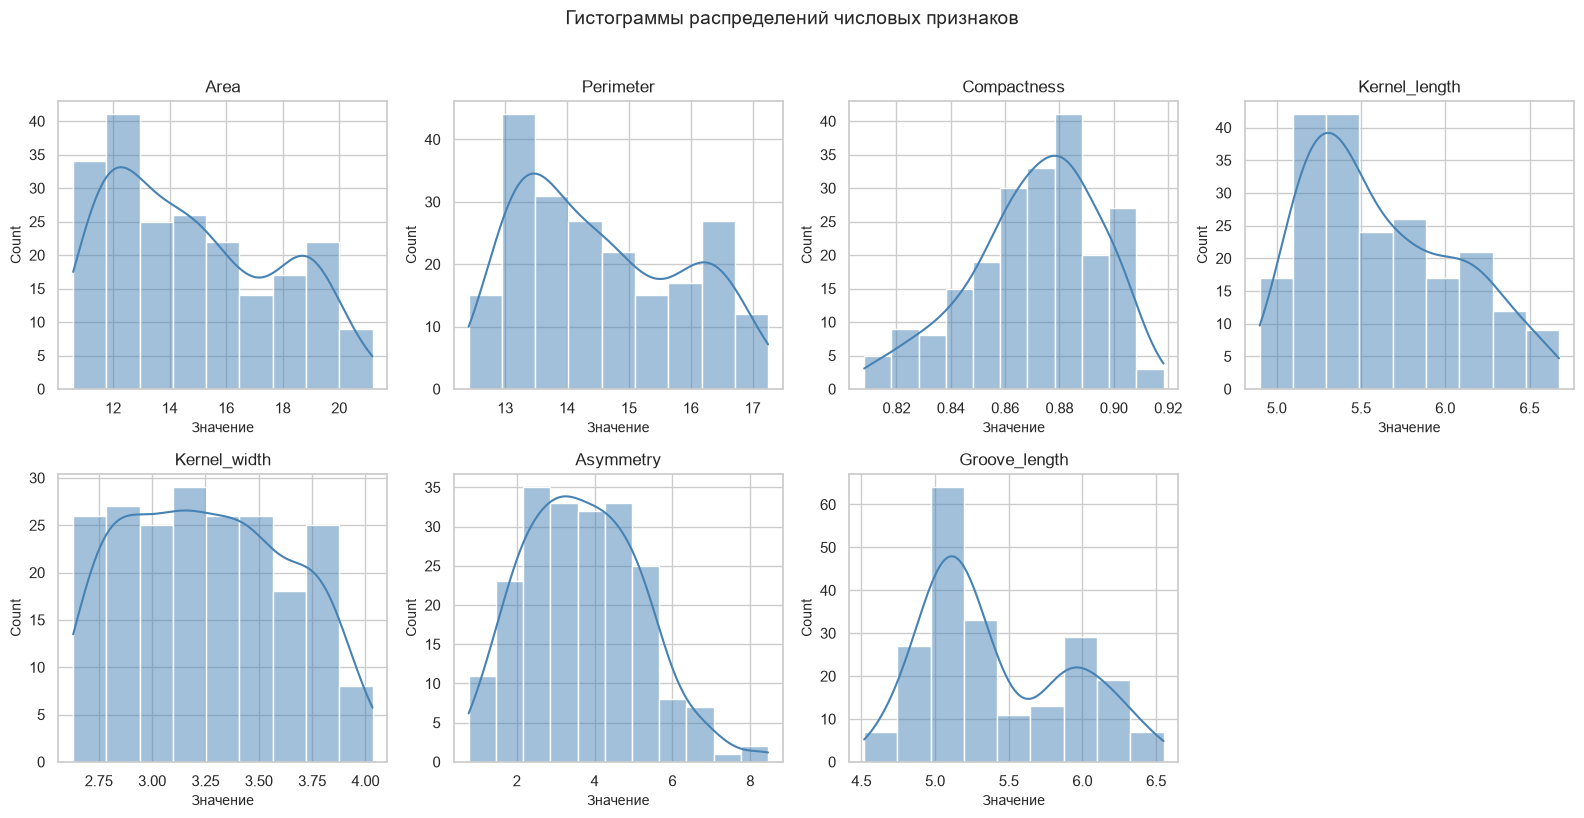

,Признак,Статистика Shapiro,p-value,Вывод при alpha=0.05
0,Area,0.9326,0.0000,отклонение от нормальности
1,Perimeter,0.9362,0.0000,отклонение от нормальности
2,Compactness,0.9730,0.0005,отклонение от нормальности
3,Kernel_length,0.9438,0.0000,отклонение от нормальности
4,Kernel_width,0.9606,0.0000,отклонение от нормальности
5,Asymmetry,0.9836,0.0154,отклонение от нормальности
6,Groove_length,0.9249,0.0000,отклонение от нормальности


In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
for i, col in enumerate(feature_names):
    sns.histplot(data[col], kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(col)
    axes[i].set_xlabel("Значение")
axes[-1].axis("off")
plt.suptitle("Гистограммы распределений числовых признаков", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

normality = []
for col in feature_names:
    stat, p_value = shapiro(data[col])
    normality.append({"Признак": col, "Статистика Shapiro": stat, "p-value": p_value,
                      "Вывод при alpha=0.05": "нет оснований отвергнуть нормальность" if p_value >= 0.05 else "отклонение от нормальности"})
normality_df = pd.DataFrame(normality)
display(normality_df.round(4))

**Пояснение.** Гистограммы позволяют визуально оценить симметрию, асимметрию, мультимодальность и возможные длинные хвосты. Тест Шапиро–Уилка проверяет нулевую гипотезу о нормальном распределении: при `p-value < 0,05` она отвергается. Для кластеризации K-means и Agglomerative нормальность каждого признака не является обязательным условием; результаты теста используются как описательная характеристика данных, а не как автоматический критерий исключения признаков.

### 3.4. Корреляции и информационная значимость признаков

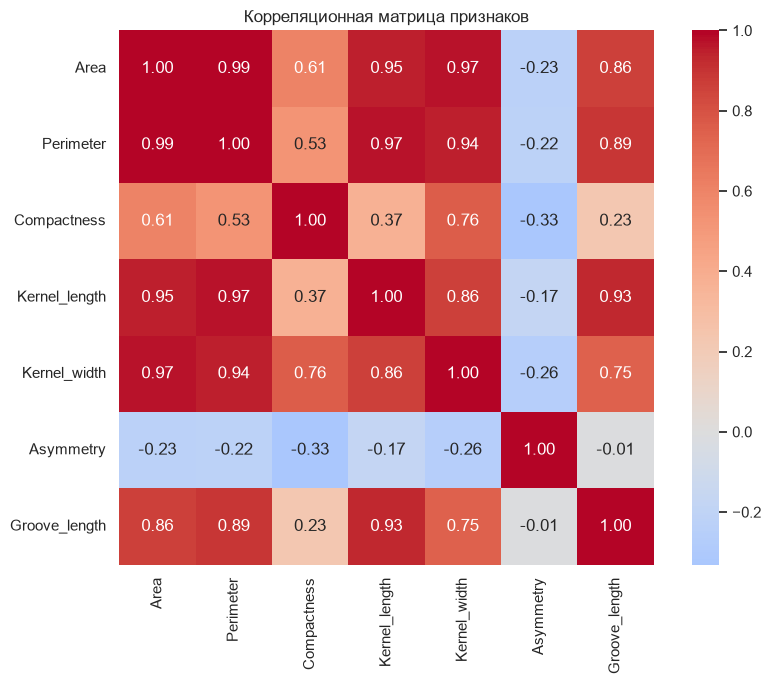

,Признак,ANOVA F,p-value
0,Area,548.186479,0.0
1,Perimeter,541.579497,0.0
4,Kernel_width,406.302031,0.0
6,Groove_length,368.950045,0.0
3,Kernel_length,322.185934,0.0
2,Compactness,75.869048,0.0
5,Asymmetry,51.888109,0.0


In [5]:
corr = X.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()

# Ретроспективная оценка разделимости признаков по известным сортам.
# Этот анализ НЕ используется для отбора признаков перед кластеризацией.
f_stats, p_values = f_classif(X, y_true)
feature_relevance = pd.DataFrame({
    "Признак": feature_names, "ANOVA F": f_stats, "p-value": p_values
}).sort_values("ANOVA F", ascending=False)
display(feature_relevance.round(6))

**Пояснение.** Корреляционная матрица показывает линейную связь между характеристиками: сильная корреляция означает, что часть признаков может описывать близкие свойства зёрен. Таблица ANOVA F и p-value приведена только как дополнительная ретроспективная оценка того, насколько признаки различаются между известными разновидностями. Это не является обучением кластеризатора по меткам: все семь признаков сохраняются, а `y_true` не используется при построении кластеров. Такой подход позволяет избежать утечки эталонных классов в алгоритм обучения.

### 3.5. Выбросы и применимость кластеризации

,Признак,Нижняя граница,Верхняя граница,Число потенциальных выбросов
0,Area,4.717,24.858,0
1,Perimeter,10.052,19.112,0
2,Compactness,0.811,0.934,3
3,Kernel_length,4.186,7.056,0
4,Kernel_width,2.017,4.488,0
5,Asymmetry,-0.749,8.080,2
6,Groove_length,3.797,7.125,0


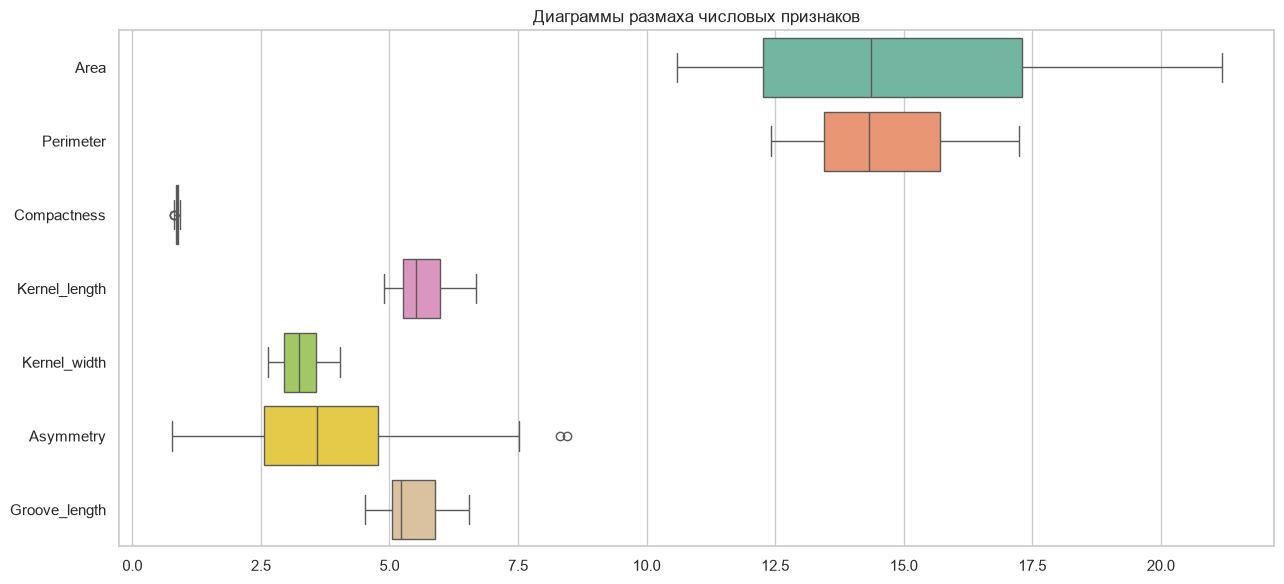

In [6]:
# Выбросы по правилу 1.5*IQR для каждого признака
outlier_rows = []
for col in feature_names:
    q1, q3 = X[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((X[col] < lower) | (X[col] > upper)).sum()
    outlier_rows.append({"Признак": col, "Нижняя граница": lower, "Верхняя граница": upper, "Число потенциальных выбросов": count})
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(3))

plt.figure(figsize=(13, 6))
sns.boxplot(data=X, orient="h")
plt.title("Диаграммы размаха числовых признаков")
plt.tight_layout()
plt.show()

**Пояснение.** Потенциальные выбросы отмечаются по правилу Тьюки: за пределами интервала `[Q1 − 1,5·IQR; Q3 + 1,5·IQR]`. Это диагностический критерий, а не доказательство ошибочности измерения. Для данного набора необычные измерения могут отражать естественную изменчивость зёрен. Поэтому объекты не удаляются автоматически: удаление могло бы исказить структуру выборки. В дальнейшем применяется StandardScaler; влияние экстремальных наблюдений учитывается при интерпретации результатов, поскольку среднее и стандартное отклонение чувствительны к выбросам.

**Вывод об условиях применения.** Признаки имеют предметный смысл (геометрические характеристики зерна), расстояние в стандартизированном пространстве можно интерпретировать как сходство профилей измерений, а три группы допускают содержательную проверку по сортам. Следовательно, кластеризация обоснована. При этом исходные метки сортов используются только для внешней оценки.

## 4. Предобработка данных

### 4.1. Стандартизация

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_names, index=X.index)

scaled_stats = pd.DataFrame({
    "Среднее после масштабирования": X_scaled_df.mean(),
    "Стандартное отклонение после масштабирования": X_scaled_df.std(ddof=0)
})
display(scaled_stats.round(4))

,Среднее после масштабирования,Стандартное отклонение после масштабирования
Area,-0.0,1.0
Perimeter,0.0,1.0
Compactness,0.0,1.0
Kernel_length,-0.0,1.0
Kernel_width,-0.0,1.0
Asymmetry,-0.0,1.0
Groove_length,-0.0,1.0


**Пояснение.** Использован `StandardScaler`: каждый признак преобразуется по формуле `z = (x − mean) / std`, поэтому среднее становится близким к нулю, а стандартное отклонение — к единице. Выбор обоснован тем, что оба выбранных алгоритма используют расстояния между объектами/группами. Без масштабирования признаки с большими числовыми значениями могли бы непропорционально влиять на расстояния. Масштабирование выполнено по всем объектам, так как здесь решается задача описательной кластеризации всего набора, а не прогнозирования на отложенной тестовой выборке.

### 4.2. Матрица диаграмм рассеивания

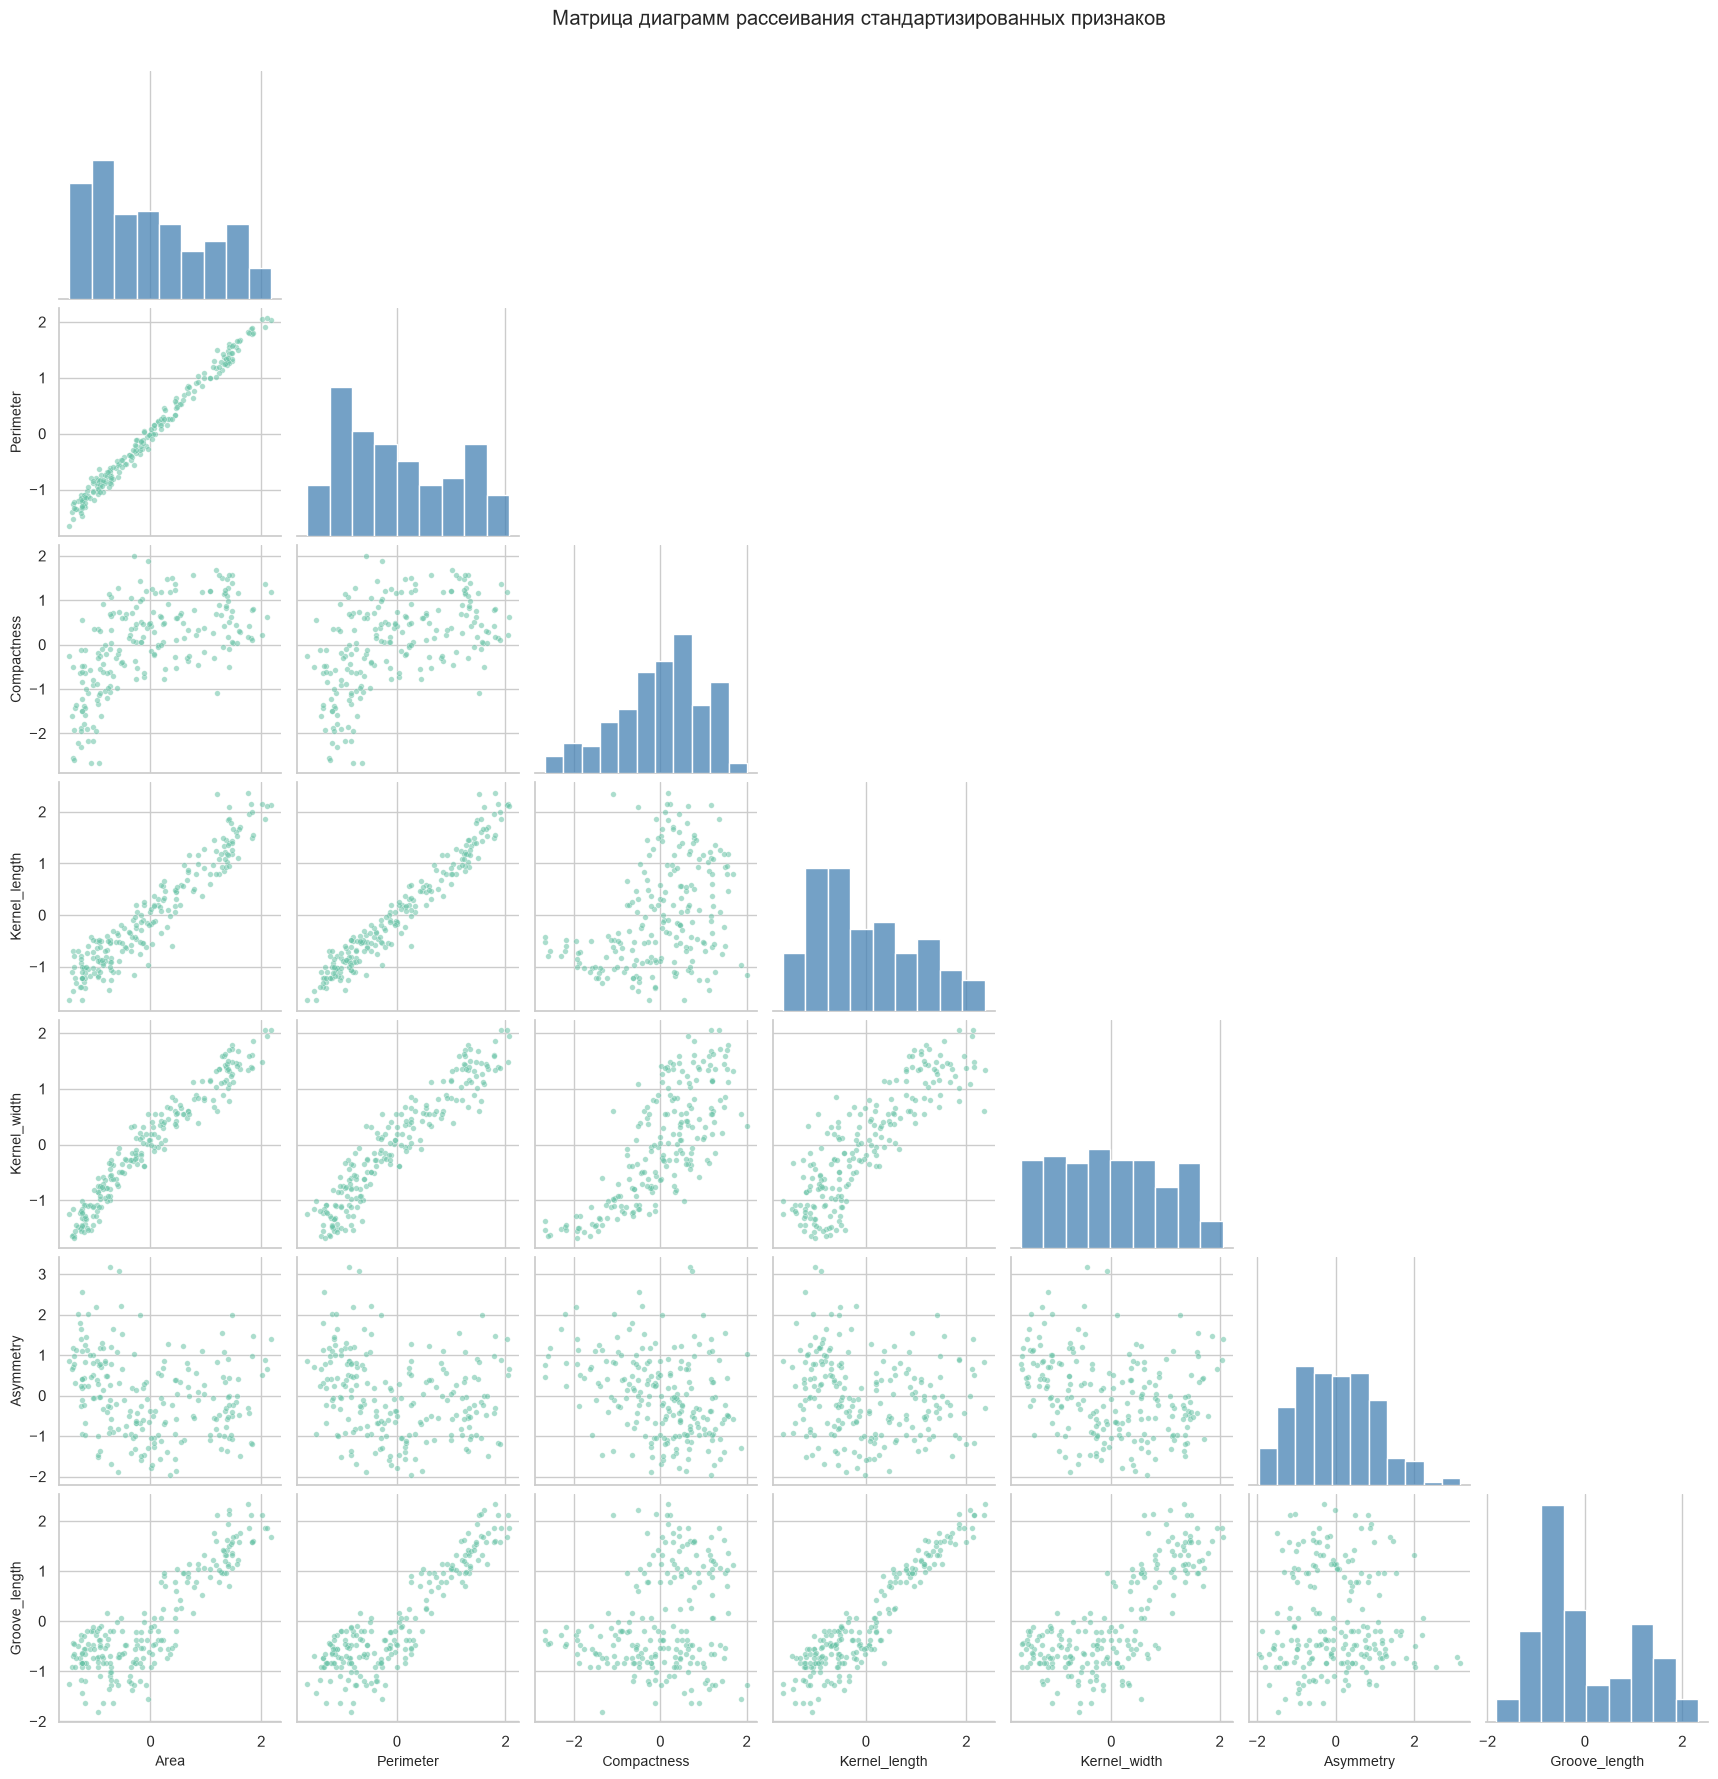

In [8]:
pairplot_data = X_scaled_df.copy()
# Для компактности и читаемости показываем все 7 стандартизированных признаков.
g = sns.pairplot(pairplot_data, corner=True, diag_kind="hist", plot_kws={"s": 16, "alpha": 0.55}, diag_kws={"color": "steelblue"})
g.fig.suptitle("Матрица диаграмм рассеивания стандартизированных признаков", y=1.02)
plt.show()

**Пояснение.** Матрица диаграмм рассеивания позволяет оценить форму облаков точек в попарных проекциях, наличие разделённых областей, перекрытий и возможных выбросов. Если группы имеют приблизительно компактную форму, K-means и метод Уорда являются разумными кандидатами. Если бы наблюдались вытянутые/неправильные области или сильно различающаяся плотность, следовало бы дополнительно рассмотреть DBSCAN. Парные двумерные проекции не гарантируют, что структура полностью видна во всех семи измерениях.

## 5. Подбор числа кластеров

### 5.1. Метод локтя и силуэтный анализ для K-means

,k,Inertia,Silhouette
0,2,659.1718,0.4658
1,3,430.6590,0.4007
2,4,371.3017,0.3276
3,5,326.5137,0.2849
4,6,289.8040,0.2798
5,7,262.9736,0.2709
6,8,240.6426,0.2510


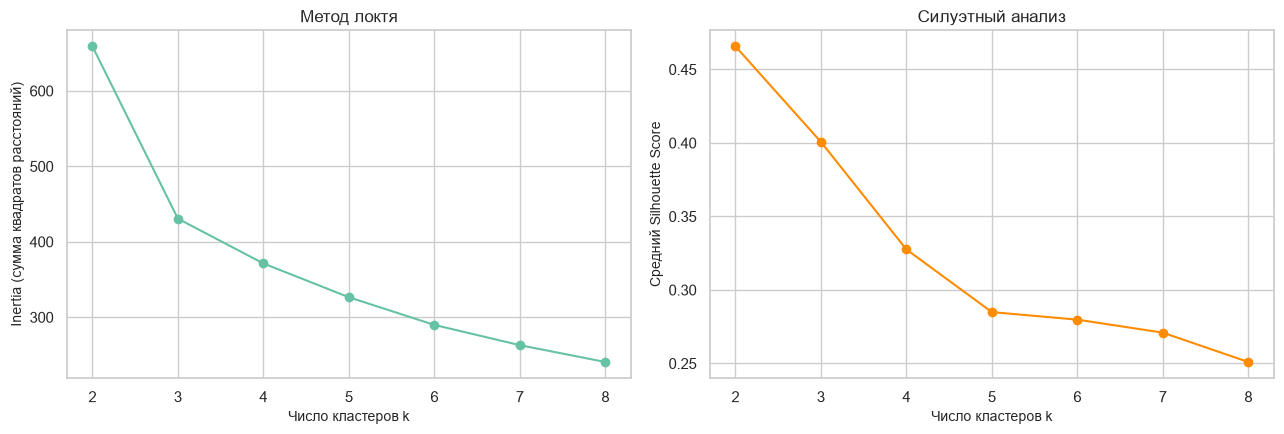

k с максимальным средним silhouette: 2


In [9]:
k_values = range(2, 9)
elbow_results = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    elbow_results.append({"k": k, "Inertia": model.inertia_, "Silhouette": silhouette_score(X_scaled, labels)})
k_results = pd.DataFrame(elbow_results)
display(k_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_results["k"], k_results["Inertia"], marker="o")
axes[0].set_title("Метод локтя")
axes[0].set_xlabel("Число кластеров k")
axes[0].set_ylabel("Inertia (сумма квадратов расстояний)")
axes[1].plot(k_results["k"], k_results["Silhouette"], marker="o", color="darkorange")
axes[1].set_title("Силуэтный анализ")
axes[1].set_xlabel("Число кластеров k")
axes[1].set_ylabel("Средний Silhouette Score")
plt.tight_layout()
plt.show()

best_k_silhouette = int(k_results.loc[k_results["Silhouette"].idxmax(), "k"])
print("k с максимальным средним silhouette:", best_k_silhouette)

**Пояснение.** Инерция K-means закономерно уменьшается при увеличении `k`; методом локтя выбирают область, где дальнейшее добавление кластеров даёт уже небольшое улучшение. Silhouette Score оценивает одновременно компактность и отделённость групп; значение ближе к 1 предпочтительнее, около 0 указывает на перекрытие, отрицательное — на возможное неверное назначение. Итоговое `k` выбирается с учётом обоих графиков и предметного смысла трёх разновидностей, а не только по одному максимуму метрики.

### 5.2. Дендрограмма и выбор числа кластеров для иерархического метода

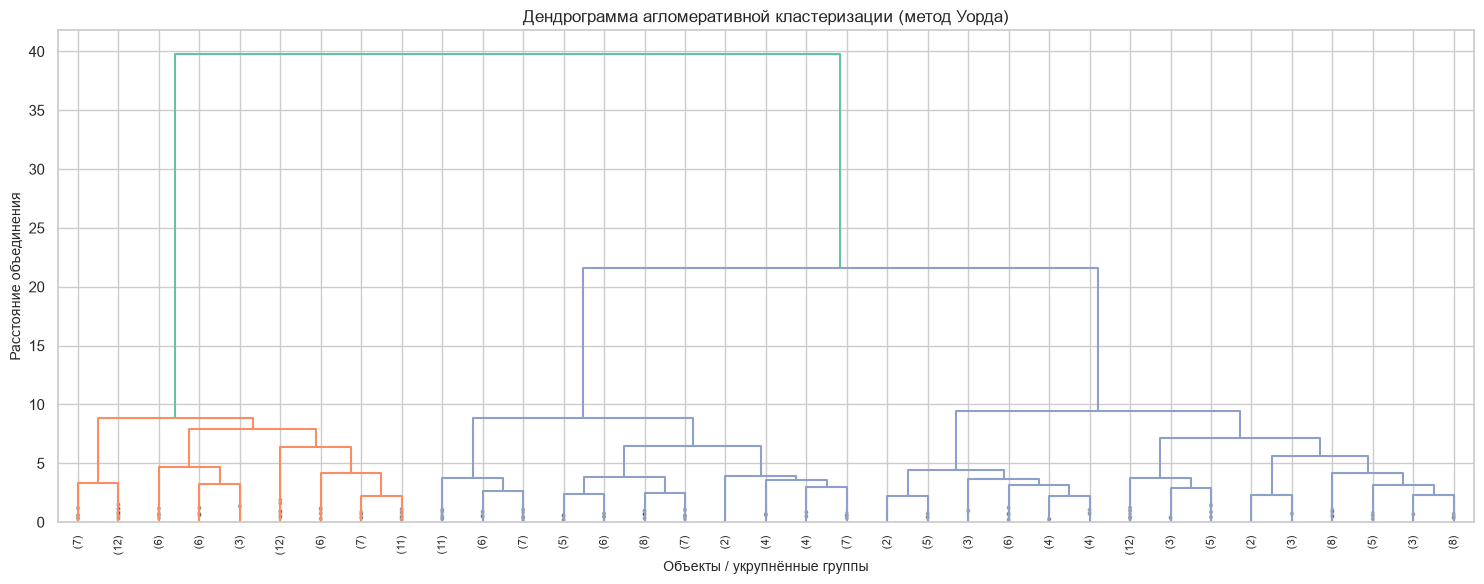

In [10]:
Z = linkage(X_scaled, method="ward", metric="euclidean")
plt.figure(figsize=(15, 6))
dendrogram(Z, truncate_mode="lastp", p=35, leaf_rotation=90, leaf_font_size=8,
           show_contracted=True)
plt.title("Дендрограмма агломеративной кластеризации (метод Уорда)")
plt.xlabel("Объекты / укрупнённые группы")
plt.ylabel("Расстояние объединения")
plt.tight_layout()
plt.show()

**Пояснение.** Агломеративная кластеризация начинает с отдельных объектов и последовательно объединяет ближайшие группы. Метод Уорда выбирает объединения, минимизирующие прирост внутрикластерной суммы квадратов. На дендрограмме высота ветви отражает расстояние (уровень неоднородности) при слиянии; большой вертикальный скачок может указывать на естественный уровень разреза. Для сравнения с K-means далее проверяются варианты числа кластеров, а итоговый выбор делается по внутренним метрикам и интерпретируемости.

### 5.3. Сравнение числа кластеров для Agglomerative Clustering

,k,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0.4613,242.7120,0.7829
1,3,0.3926,238.3612,0.9445
2,4,0.3006,183.2004,1.2127
3,5,0.2746,157.1568,1.2329
4,6,0.2150,145.2228,1.2984
5,7,0.2320,137.1924,1.2743
6,8,0.2327,131.0170,1.2721


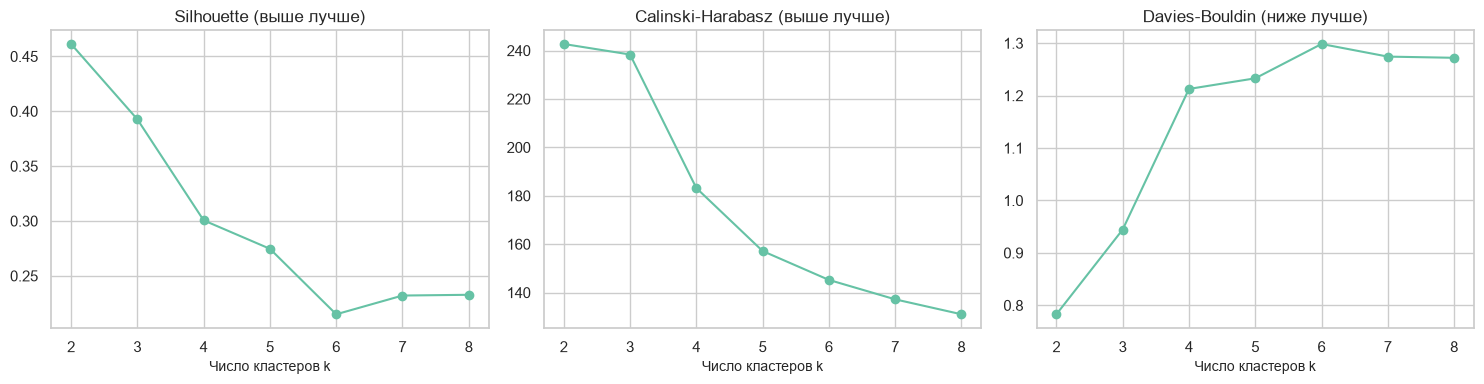

In [11]:
agg_k_results = []
for k in range(2, 9):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_scaled)
    agg_k_results.append({"k": k, "Silhouette": silhouette_score(X_scaled, labels),
                          "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
                          "Davies-Bouldin": davies_bouldin_score(X_scaled, labels)})
agg_k_df = pd.DataFrame(agg_k_results)
display(agg_k_df.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(axes, ["Silhouette", "Calinski-Harabasz", "Davies-Bouldin"],
                            ["Silhouette (выше лучше)", "Calinski-Harabasz (выше лучше)", "Davies-Bouldin (ниже лучше)"]):
    ax.plot(agg_k_df["k"], agg_k_df[metric], marker="o")
    ax.set_xlabel("Число кластеров k")
    ax.set_title(title)
plt.tight_layout()
plt.show()

**Пояснение.** Для иерархического алгоритма также рассчитаны три внутренние метрики при `k` от 2 до 8. Silhouette и Calinski–Harabasz желательно максимизировать, Davies–Bouldin — минимизировать. Метрики могут указывать на разные значения `k`, поэтому решение принимается комплексно. С учётом предметной постановки дополнительно проверяется разбиение на три группы, соответствующие трём известным разновидностям; метки сортов не влияют на построение разбиения.

## 6. Реализация двух методов кластеризации

### 6.1. K-means

In [12]:
# В качестве основного решения фиксируем k=3: в наборе три разновидности
# (метки не используются для обучения), а выбор дополнительно проверяется графиками выше.
K_FINAL = 3
kmeans = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)

print("Размеры кластеров K-means:")
display(pd.Series(labels_kmeans).value_counts().sort_index().rename("Количество объектов").to_frame())
print("Инерция K-means:", round(kmeans.inertia_, 4))

Размеры кластеров K-means:


,Количество объектов
0,72
1,67
2,71


Инерция K-means: 430.659


**Пояснение.** K-means относит каждый объект к ближайшему центру, после чего пересчитывает центр как среднее объектов кластера. Процесс повторяется до стабилизации. В реализации использованы `n_init=10` (десять начальных запусков) и фиксированное случайное состояние. Для итогового сравнения установлено `k=3`, поскольку датасет содержит три разновидности зёрен; при этом алгоритм не получает истинные метки. 

### 6.2. Агломеративная иерархическая кластеризация

In [13]:
agglomerative = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward")
labels_agg = agglomerative.fit_predict(X_scaled)

print("Размеры кластеров Agglomerative:")
display(pd.Series(labels_agg).value_counts().sort_index().rename("Количество объектов").to_frame())

Размеры кластеров Agglomerative:


,Количество объектов
0,73
1,70
2,67


**Пояснение.** Agglomerative Clustering строит иерархию снизу вверх: сначала каждый объект является отдельным кластером, затем ближайшие группы объединяются до получения трёх итоговых кластеров. Выбран `linkage="ward"`, поскольку он ориентирован на компактные группы и согласуется с евклидовым расстоянием в стандартизированном пространстве. В отличие от K-means, иерархический алгоритм не требует случайной инициализации центров.

## 7. Оценка качества кластеризации

### 7.1. Внутренние метрики и сравнение алгоритмов

In [14]:
def internal_metrics(X_array, labels):
    return {
        "Silhouette Score": silhouette_score(X_array, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_array, labels),
        "Davies-Bouldin": davies_bouldin_score(X_array, labels)
    }

comparison_internal = pd.DataFrame({
    "K-means": internal_metrics(X_scaled, labels_kmeans),
    "Agglomerative (Ward)": internal_metrics(X_scaled, labels_agg)
}).T
display(comparison_internal.round(4))

,Silhouette Score,Calinski-Harabasz,Davies-Bouldin
K-means,0.4007,249.7842,0.9279
Agglomerative (Ward),0.3926,238.3612,0.9445


**Пояснение.** Внутренние метрики не требуют эталонных классов и оценивают геометрию самого разбиения. Silhouette Score лежит в диапазоне от −1 до 1: чем выше, тем лучше объект вписан в свой кластер и отделён от соседнего. Calinski–Harabasz сравнивает межкластерный и внутрикластерный разброс (выше — лучше). Davies–Bouldin оценивает сходство кластеров через их разброс и расстояния между центрами (ниже — лучше). метрики описывают выбранную геометрию, но не смысл групп.

### 7.2. Внешние метрики: сравнение с известными сортами

In [15]:
def external_metrics(y_true, labels):
    return {
        "Rand Index": rand_score(y_true, labels),
        "Adjusted Rand Index (ARI)": adjusted_rand_score(y_true, labels),
        "Normalized Mutual Information": normalized_mutual_info_score(y_true, labels),
        "Homogeneity": homogeneity_score(y_true, labels),
        "Completeness": completeness_score(y_true, labels),
        "V-measure": v_measure_score(y_true, labels)
    }

comparison_external = pd.DataFrame({
    "K-means": external_metrics(y_true, labels_kmeans),
    "Agglomerative (Ward)": external_metrics(y_true, labels_agg)
}).T
display(comparison_external.round(4))

,Rand Index,Adjusted Rand Index (ARI),Normalized Mutual Information,Homogeneity,Completeness,V-measure
K-means,0.8997,0.7733,0.7279,0.7277,0.728,0.7279
Agglomerative (Ward),0.9102,0.7970,0.7498,0.7496,0.750,0.7498


**Пояснение.** Внешние метрики сравнивают найденное разбиение с известными разновидностями, которые не участвовали в обучении. Rand Index оценивает согласованность пар объектов, ARI корректирует совпадение на случайный уровень (1 означает полное совпадение с точностью до перенумерации кластеров). NMI измеряет нормированную взаимную информацию; homogeneity показывает, насколько каждый кластер содержит объекты одного сорта, completeness — насколько объекты одного сорта собраны вместе, V-measure является их гармоническим средним. Номера кластеров произвольны, поэтому сравнение выполняется по структуре разбиения, а не по совпадению номеров. 

### 7.3. Размеры, центры и внутрикластерные расстояния

In [16]:
def cluster_geometry(X_original, X_standardized, labels, scaler, feature_names):
    rows = []
    centers_scaled = []
    centers_original = []
    for cluster_id in sorted(np.unique(labels)):
        mask = labels == cluster_id
        cluster_scaled = X_standardized[mask]
        center_scaled = cluster_scaled.mean(axis=0)
        center_original = scaler.inverse_transform(center_scaled.reshape(1, -1))[0]
        distances = np.linalg.norm(cluster_scaled - center_scaled, axis=1)
        centers_scaled.append(center_scaled)
        centers_original.append(center_original)
        rows.append({
            "Кластер": int(cluster_id), "Размер": int(mask.sum()),
            "Среднее расстояние до центра": distances.mean(),
            "Максимальное расстояние до центра": distances.max(),
            "Внутрикластерная сумма квадратов": np.sum(distances ** 2)
        })
    centers_df = pd.DataFrame(centers_original, columns=feature_names,
                              index=[f"Кластер {i}" for i in sorted(np.unique(labels))])
    return pd.DataFrame(rows), centers_df, np.asarray(centers_scaled)

geom_kmeans, centers_kmeans, centers_kmeans_scaled = cluster_geometry(X, X_scaled, labels_kmeans, scaler, feature_names)
geom_agg, centers_agg, centers_agg_scaled = cluster_geometry(X, X_scaled, labels_agg, scaler, feature_names)
print("Геометрия кластеров K-means:")
display(geom_kmeans.round(4))
print("Центры K-means в исходных единицах измерения:")
display(centers_kmeans.round(3))
print("Геометрия кластеров Agglomerative:")
display(geom_agg.round(4))
print("Центры Agglomerative в исходных единицах измерения:")
display(centers_agg.round(3))

Геометрия кластеров K-means:


,Кластер,Размер,Среднее расстояние до центра,Максимальное расстояние до центра,Внутрикластерная сумма квадратов
0,0,72,1.2997,3.1484,145.2873
1,1,67,1.3657,2.4056,140.2219
2,2,71,1.3211,2.7364,145.1498


Центры K-means в исходных единицах измерения:


,Area,Perimeter,Compactness,Kernel_length,Kernel_width,Asymmetry,Groove_length
Кластер 0,11.857,13.248,0.848,5.232,2.850,4.742,5.102
Кластер 1,18.495,16.203,0.884,6.176,3.698,3.632,6.042
Кластер 2,14.438,14.338,0.882,5.515,3.259,2.707,5.121


Геометрия кластеров Agglomerative:


,Кластер,Размер,Среднее расстояние до центра,Максимальное расстояние до центра,Внутрикластерная сумма квадратов
0,0,73,1.3862,2.8093,167.8848
1,1,70,1.4095,2.4421,156.4007
2,2,67,1.2406,3.0505,120.7635


Центры Agglomerative в исходных единицах измерения:


,Area,Perimeter,Compactness,Kernel_length,Kernel_width,Asymmetry,Groove_length
Кластер 0,14.199,14.234,0.879,5.478,3.226,2.612,5.086
Кластер 1,18.371,16.145,0.884,6.158,3.685,3.639,6.017
Кластер 2,11.872,13.257,0.848,5.239,2.849,4.949,5.122


**Пояснение.** Размер кластера показывает число вошедших в него зёрен. Среднее и максимальное расстояния до центра характеризуют внутрикластерный разброс; сумма квадратов расстояний отражает компактность в стандартизированном пространстве. Центры сначала вычисляются в стандартизированном пространстве, а затем переводятся обратно в исходные единицы через `inverse_transform`, чтобы их можно было интерпретировать как реальные геометрические характеристики. Для Agglomerative центры также рассчитаны как средние координаты объектов соответствующего кластера — это описательная статистика, а не параметры, используемые самим алгоритмом.

### 7.4. Расстояния между центрами кластеров

In [17]:
dist_kmeans = pd.DataFrame(pairwise_distances(centers_kmeans_scaled),
                           index=centers_kmeans.index, columns=centers_kmeans.index)
dist_agg = pd.DataFrame(pairwise_distances(centers_agg_scaled),
                        index=centers_agg.index, columns=centers_agg.index)
print("Расстояния между центрами K-means (стандартизированное пространство):")
display(dist_kmeans.round(3))
print("Расстояния между центрами Agglomerative (стандартизированное пространство):")
display(dist_agg.round(3))

Расстояния между центрами K-means (стандартизированное пространство):


,Кластер 0,Кластер 1,Кластер 2
Кластер 0,0.000,5.153,2.632
Кластер 1,5.153,0.000,3.393
Кластер 2,2.632,3.393,0.000


Расстояния между центрами Agglomerative (стандартизированное пространство):


,Кластер 0,Кластер 1,Кластер 2
Кластер 0,0.000,3.491,2.584
Кластер 1,3.491,0.000,5.064
Кластер 2,2.584,5.064,0.000


**Пояснение.** Матрицы показывают евклидовы расстояния между центрами кластеров в одном и том же стандартизированном пространстве. Нулевые значения на диагонали соответствуют расстоянию центра до самого себя. Чем больше расстояние между двумя центрами относительно внутрикластерного разброса, тем лучше эти группы разделены. Для оценки нельзя рассматривать расстояния между центрами отдельно от размеров и разброса кластеров.

### 7.5. Сводная сравнительная таблица

In [18]:
summary = pd.concat([comparison_internal, comparison_external], axis=1)
summary["Число кластеров"] = [len(np.unique(labels_kmeans)), len(np.unique(labels_agg))]
summary["Минимальный размер кластера"] = [pd.Series(labels_kmeans).value_counts().min(), pd.Series(labels_agg).value_counts().min()]
summary["Максимальный размер кластера"] = [pd.Series(labels_kmeans).value_counts().max(), pd.Series(labels_agg).value_counts().max()]
display(summary.round(4))

,Silhouette Score,Calinski-Harabasz,Davies-Bouldin,Rand Index,Adjusted Rand Index (ARI),Normalized Mutual Information,Homogeneity,Completeness,V-measure,Число кластеров,Минимальный размер кластера,Максимальный размер кластера
K-means,0.4007,249.7842,0.9279,0.8997,0.7733,0.7279,0.7277,0.728,0.7279,3,67,72
Agglomerative (Ward),0.3926,238.3612,0.9445,0.9102,0.7970,0.7498,0.7496,0.750,0.7498,3,67,73


**Пояснение.** Сводная таблица объединяет внутренние и внешние показатели, а также баланс размеров групп. При выборе более подходящего метода следует учитывать несколько критериев одновременно: высокие Silhouette/CH/ARI/NMI/V-measure, низкий Davies–Bouldin и отсутствие неоправданно малых кластеров. Нельзя объявлять алгоритм лучшим только по одной метрике: внутренние и внешние показатели отвечают на разные вопросы.

## 8. Исследование влияния параметра k для K-means

,k,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI
0,2,659.1718,0.4658,255.8548,0.7969,0.4805
1,3,430.6590,0.4007,249.7842,0.9279,0.7733
2,4,371.3017,0.3276,203.1877,1.0626,0.6624
3,5,326.5137,0.2849,179.4830,1.1825,0.5211
4,6,289.8040,0.2798,166.1536,1.1457,0.4719
5,7,262.9736,0.2709,155.2921,1.1864,0.3805
6,8,240.6426,0.2510,147.4209,1.2497,0.3192


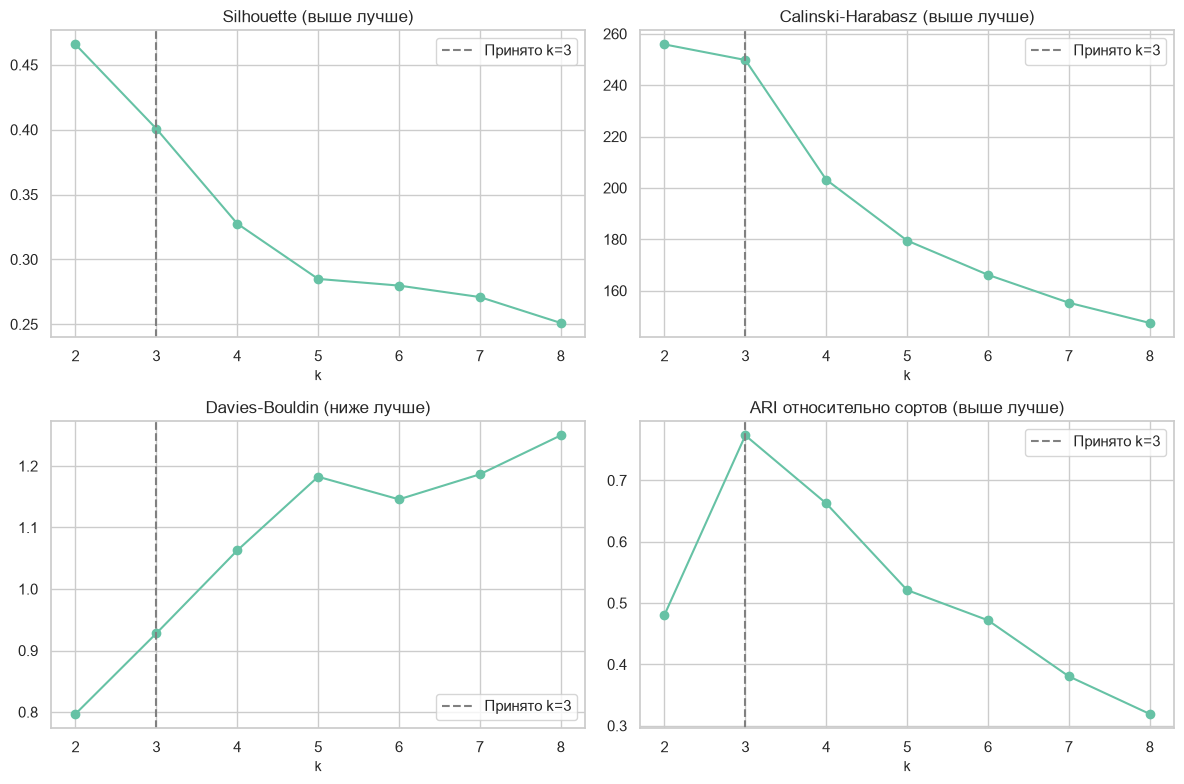

In [19]:
sensitivity = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    sensitivity.append({
        "k": k, "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "ARI": adjusted_rand_score(y_true, labels)
    })
sensitivity_df = pd.DataFrame(sensitivity)
display(sensitivity_df.round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
metrics_to_plot = [("Silhouette", "Silhouette (выше лучше)"),
                    ("Calinski-Harabasz", "Calinski-Harabasz (выше лучше)"),
                    ("Davies-Bouldin", "Davies-Bouldin (ниже лучше)"),
                    ("ARI", "ARI относительно сортов (выше лучше)")]
for ax, (metric, title) in zip(axes.ravel(), metrics_to_plot):
    ax.plot(sensitivity_df["k"], sensitivity_df[metric], marker="o")
    ax.axvline(K_FINAL, color="gray", linestyle="--", label=f"Принято k={K_FINAL}")
    ax.set_xlabel("k")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

**Пояснение.** При увеличении `k` инерция обычно уменьшается, поскольку каждый объект получает более близкий центр, однако слишком большое число кластеров приводит к дроблению естественных групп. На графиках сравнивается влияние `k` на внутренние показатели и ARI. ARI используется только для постфактум-проверки соответствия известным сортам. Выбранное `k=3` следует оценить по форме кривых: если метрики улучшаются незначительно при дальнейшем росте `k`, три кластера дают более компактное и интерпретируемое решение без избыточного дробления.

## 9. Визуализация результатов

### 9.1. PCA: проекция данных на две главные компоненты

Доля объяснённой дисперсии PC1 и PC2: [0.7187 0.1711]
Суммарная доля объяснённой дисперсии: 0.8898


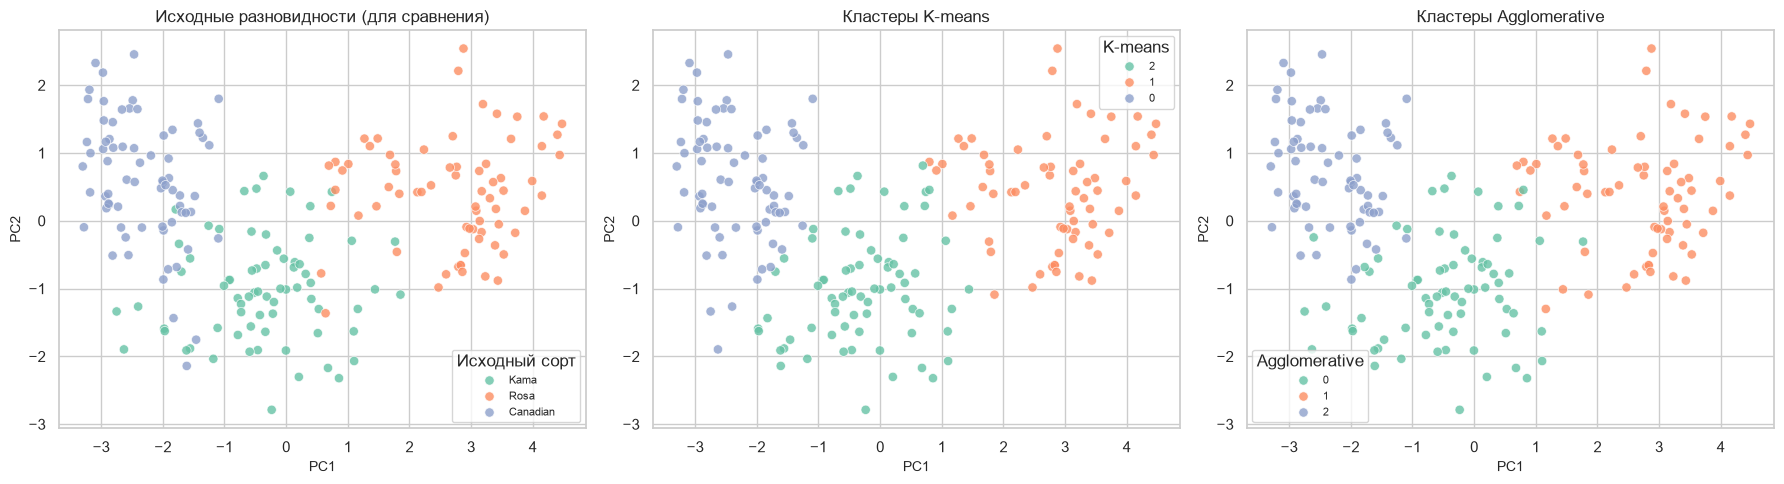

In [20]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Доля объяснённой дисперсии PC1 и PC2:", np.round(pca.explained_variance_ratio_, 4))
print("Суммарная доля объяснённой дисперсии:", round(pca.explained_variance_ratio_.sum(), 4))

pca_df = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1],
                        "K-means": labels_kmeans.astype(str),
                        "Agglomerative": labels_agg.astype(str),
                        "Исходный сорт": y_true.map({1: "Kama", 2: "Rosa", 3: "Canadian"})})
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, title in zip(axes, ["Исходный сорт", "K-means", "Agglomerative"],
                          ["Исходные разновидности (для сравнения)", "Кластеры K-means", "Кластеры Agglomerative"]):
    sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue=col, palette="Set2", s=45, alpha=0.8, ax=ax)
    ax.set_title(title)
    ax.legend(title=col, fontsize=8)
plt.tight_layout()
plt.show()

**Пояснение.** PCA преобразует семь стандартизированных признаков в две линейные компоненты, сохраняющие максимально возможную долю дисперсии. На рисунке сопоставлены исходные сорта (только для визуальной проверки) и кластеры двух алгоритмов. Если облака точек визуально разделяются, это поддерживает вывод о наличии групп; перекрытия показывают, что разделение не идеально. Важно учитывать суммарную долю объяснённой дисперсии: двумерная проекция может скрывать часть структуры исходного семимерного пространства, поэтому метрики рассчитаны на полном наборе стандартизированных признаков.

### 9.2. Интерпретация кластеров через профили признаков

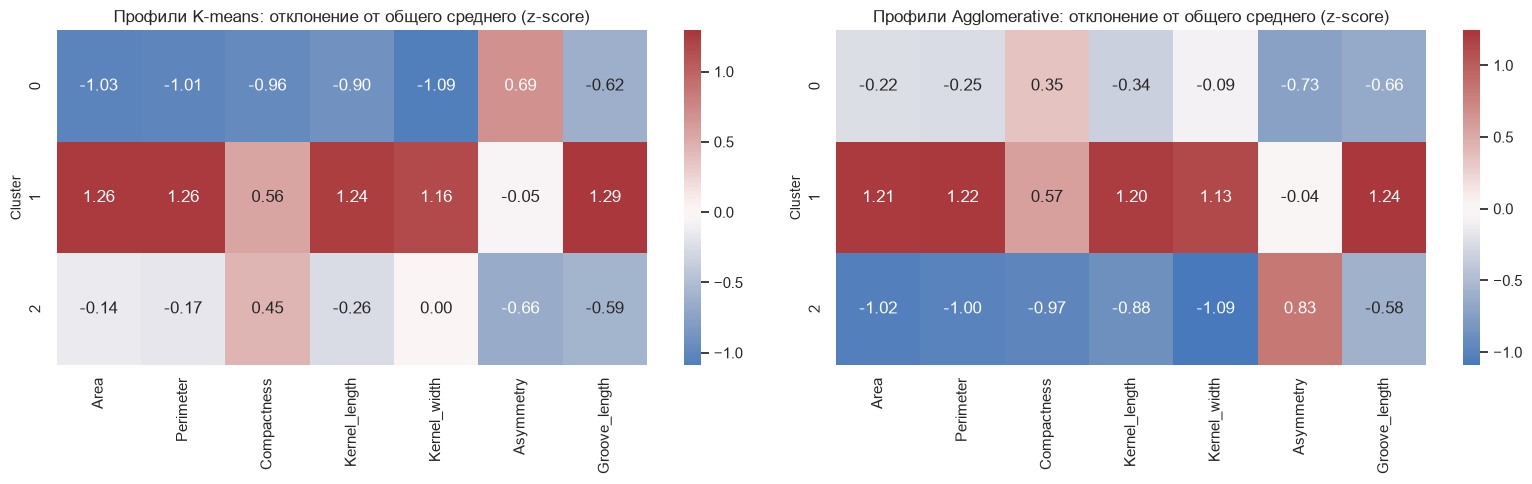

Средние значения признаков по кластерам K-means:


,Area,Perimeter,Compactness,Kernel_length,Kernel_width,Asymmetry,Groove_length
Cluster,,,,,,,
0,11.857,13.248,0.848,5.232,2.850,4.742,5.102
1,18.495,16.203,0.884,6.176,3.698,3.632,6.042
2,14.438,14.338,0.882,5.515,3.259,2.707,5.121


Средние значения признаков по кластерам Agglomerative:


,Area,Perimeter,Compactness,Kernel_length,Kernel_width,Asymmetry,Groove_length
Cluster,,,,,,,
0,14.199,14.234,0.879,5.478,3.226,2.612,5.086
1,18.371,16.145,0.884,6.158,3.685,3.639,6.017
2,11.872,13.257,0.848,5.239,2.849,4.949,5.122


In [21]:
# Сравниваем средние исходных признаков по кластерам
profile_kmeans = X.assign(Cluster=labels_kmeans).groupby("Cluster").mean()
profile_agg = X.assign(Cluster=labels_agg).groupby("Cluster").mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap((profile_kmeans - X.mean()) / X.std(ddof=0), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[0])
axes[0].set_title("Профили K-means: отклонение от общего среднего (z-score)")
sns.heatmap((profile_agg - X.mean()) / X.std(ddof=0), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Профили Agglomerative: отклонение от общего среднего (z-score)")
plt.tight_layout()
plt.show()

print("Средние значения признаков по кластерам K-means:")
display(profile_kmeans.round(3))
print("Средние значения признаков по кластерам Agglomerative:")
display(profile_agg.round(3))

**Пояснение.** Таблицы показывают средние значения семи исходных характеристик в каждом кластере. Тепловые карты отображают отклонение среднего кластера от общего среднего в единицах стандартного отклонения: положительные значения означают признак выше среднего по выборке, отрицательные — ниже. По профилям можно описать выделенные группы, например как зёрна с относительно большей площадью и шириной или с меньшей длиной и иной асимметрией. Интерпретация должна опираться на фактические значения таблиц, а не только на цвет визуализации.

### 9.3. Сопоставление кластеров и эталонных сортов

In [22]:
cross_kmeans = pd.crosstab(y_true.map({1: "Kama", 2: "Rosa", 3: "Canadian"}),
                            labels_kmeans, rownames=["Исходный сорт"], colnames=["Кластер K-means"])
cross_agg = pd.crosstab(y_true.map({1: "Kama", 2: "Rosa", 3: "Canadian"}),
                        labels_agg, rownames=["Исходный сорт"], colnames=["Кластер Agglomerative"])
print("Распределение сортов по кластерам K-means:")
display(cross_kmeans)
print("Распределение сортов по кластерам Agglomerative:")
display(cross_agg)

Распределение сортов по кластерам K-means:


Кластер K-means,0,1,2
Исходный сорт,,,
Canadian,66,0,4
Kama,6,2,62
Rosa,0,65,5


Распределение сортов по кластерам Agglomerative:


Кластер Agglomerative,0,1,2
Исходный сорт,,,
Canadian,5,0,65
Kama,64,4,2
Rosa,4,66,0


**Пояснение.** Перекрёстные таблицы показывают, сколько объектов каждого известного сорта попало в каждый найденный кластер. Идеальное соответствие выражалось бы в том, что каждый сорт преимущественно сосредоточен в отдельном кластере. Возможное смешение сортов означает, что их геометрические характеристики частично перекрываются. Номера кластеров не имеют заранее заданного значения и могут не совпадать с номерами сортов.

## 10. Итоговые выводы

In [23]:
# Формируем фактические числовые итоги для удобства написания заключения
print("ИТОГОВЫЕ ПОКАЗАТЕЛИ")
print("K-means:", comparison_internal.loc["K-means"].round(4).to_dict())
print("Agglomerative:", comparison_internal.loc["Agglomerative (Ward)"].round(4).to_dict())
print("Внешние метрики K-means:", comparison_external.loc["K-means"].round(4).to_dict())
print("Внешние метрики Agglomerative:", comparison_external.loc["Agglomerative (Ward)"].round(4).to_dict())
print("Суммарная дисперсия, объяснённая двумя компонентами PCA:", round(pca.explained_variance_ratio_.sum(), 4))

ИТОГОВЫЕ ПОКАЗАТЕЛИ
K-means: {'Silhouette Score': 0.4007, 'Calinski-Harabasz': 249.7842, 'Davies-Bouldin': 0.9279}
Agglomerative: {'Silhouette Score': 0.3926, 'Calinski-Harabasz': 238.3612, 'Davies-Bouldin': 0.9445}
Внешние метрики K-means: {'Rand Index': 0.8997, 'Adjusted Rand Index (ARI)': 0.7733, 'Normalized Mutual Information': 0.7279, 'Homogeneity': 0.7277, 'Completeness': 0.728, 'V-measure': 0.7279}
Внешние метрики Agglomerative: {'Rand Index': 0.9102, 'Adjusted Rand Index (ARI)': 0.797, 'Normalized Mutual Information': 0.7498, 'Homogeneity': 0.7496, 'Completeness': 0.75, 'V-measure': 0.7498}
Суммарная дисперсия, объяснённая двумя компонентами PCA: 0.8898


**Заключение.**

В ходе лабораторной работы исследован набор Seeds из 210 объектов, содержащий семь числовых геометрических характеристик зёрен и три исходные разновидности пшеницы. Проведены дескриптивный анализ, проверка пропусков и дубликатов, анализ распределений и корреляций, оценка потенциальных выбросов. Признаки стандартизированы методом StandardScaler, поскольку алгоритмы сравнивают объекты по расстояниям и исходные признаки имеют разные масштабы.

Реализованы K-means и агломеративная кластеризация с методом Уорда при `k=3`. Для K-means использовано `n_init=10`. Выбор трёх кластеров является компромиссом между методом локтя, дендрограммой и предметной интерпретацией. При этом внутренние метрики для `k=2` могут быть выше: это означает, что два более крупных кластера геометрически компактнее, но такое разбиение объединяет часть разновидностей. Поэтому выбор `k=3` не следует трактовать как безусловный максимум всех внутренних метрик.

Для итогового разбиения K-means получены Silhouette = **0,4007**, Calinski–Harabasz = **249,7842**, Davies–Bouldin = **0,9279**. Для Agglomerative (Ward): Silhouette = **0,3926**, Calinski–Harabasz = **238,3612**, Davies–Bouldin = **0,9445**. По внутренним метрикам K-means немного лучше: кластеры в среднем компактнее и лучше разделены согласно выбранным критериям.

Внешняя оценка дала следующие результаты: ARI K-means = **0,7733**, ARI Agglomerative = **0,7970**; NMI соответственно **0,7279** и **0,7498**. Следовательно, иерархический метод несколько лучше согласуется с известными разновидностями, хотя немного уступает K-means по внутренним метрикам. Перекрёстные таблицы показывают, что оба метода достаточно хорошо выделяют три группы; в обоих случаях остаётся некоторое смешение объектов. Номера кластеров условны и не соответствуют номерам сортов напрямую.

PCA-проекция двух главных компонент объясняет около **88,98%** общей дисперсии, поэтому двумерная визуализация достаточно информативна, хотя окончательная оценка метрик выполнена в полном семимерном пространстве. Влияние параметра `k` показало, что при увеличении числа кластеров инерция уменьшается, но после `k=3` силуэт и ARI ухудшаются, что указывает на избыточное дробление групп.

**Общий вывод:** оба алгоритма подходят для данного набора данных. K-means предпочтительнее по внутренним геометрическим метрикам и простоте интерпретации центров; Agglomerative (Ward) показывает несколько лучшее совпадение с эталонным разбиением. Выбор метода зависит от цели: компактность геометрических групп или более точное восстановление известных разновидностей. Внешние метрики использовались только для итоговой проверки, а не для обучения кластеризаторов.

## 11. Список источников

1. Учебная лекция «Классификация. Глубокое обучение. Кластеризация», Новосибирский государственный технический университет НЭТИ. Раздел «Кластеризация», с. 104–124 (условия применения, K-means, иерархическая кластеризация, критерии выбора числа кластеров, внутренние и внешние метрики).
2. UCI Machine Learning Repository. *Seeds Data Set*. https://archive.ics.uci.edu/dataset/236/seeds
3. Scikit-learn documentation. *StandardScaler*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
4. Scikit-learn documentation. *KMeans*. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
5. Scikit-learn documentation. *AgglomerativeClustering*. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html
6. Scikit-learn documentation. *Clustering performance evaluation*. https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation